In [40]:
# importing relevant packages
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [41]:
# load in raw data that was previously saved
v_avg_df = pd.read_csv("C:/Users/robtk/OneDrive/Desktop/langevin dynamics average velocity.txt", sep = " &                  ",
                      index_col = 0,
                      engine = "python")
# Wrangle the data into a table of numbers
i = 0
while i < len(v_avg_df["mean velocity for R(0,3)"]):
    v_avg_df.iloc[i,2] = float(v_avg_df.iloc[i,2][0:8])
    i += 1
    
v_avg_df

,"mean velocity for R(0,1)","mean velocity for R(0,2)","mean velocity for R(0,3)"
0,0.349823,0.346981,0.0744
1,0.330785,0.347085,0.333107
2,0.333523,0.359348,0.068856
3,0.339839,0.354607,0.326694
4,0.322902,0.329424,0.094981
...,...,...,...
94,0.346596,0.363541,0.348282
95,0.343085,0.356809,0.281234
96,0.361531,0.360404,0.320131
97,0.366873,0.298948,0.080468


In [43]:
T_avg_df = pd.read_csv("C:/Users/robtk/OneDrive/Desktop/langevin dynamics average temperature.txt", sep = " &                  ",
                      index_col = 0,
                      engine = "python")
# Wrangle the data into a table of numbers
i = 0
while i < len(T_avg_df.iloc[:,2]):
    T_avg_df.iloc[i,2] = float(T_avg_df.iloc[i,2][0:11])
    i += 1
T_avg_df


,"mean temperature for R(0,1)","mean temperature for R(0,2)","mean temperature for R(0,3)"
0,0.122376,0.120396,0.005535
1,0.109419,0.120468,0.11096
2,0.111238,0.129131,0.004741
3,0.115491,0.125746,0.106729
4,0.104266,0.108520,0.009021
...,...,...,...
94,0.120129,0.132162,0.1213
95,0.117707,0.127312,0.079093
96,0.130705,0.129891,0.102484
97,0.134596,0.089370,0.006475


In [2]:
# Notation
# x = position
# v = velocity
# a = acceleration
# R = Random number following Gaussian distribution with mean 0 and 
# sigma_R = standard deviation of R
# gamma = friction coefficient

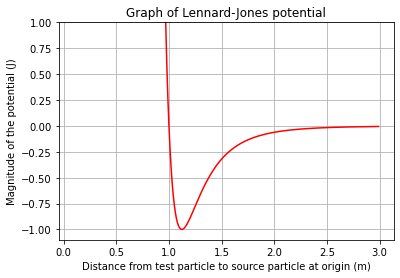

In [44]:
# Graph of the Lennard-Jones potential
x = np.arange(0.1, 3, 0.01)
y = 4*(1/x**12 - 1/x**6)
plt.plot(x, y, "r")
plt.ylim(-1.1,1)
plt.grid(True)
plt.title("Graph of Lennard-Jones potential")

plt.xlabel("Distance from test particle to source particle at origin (m)")
plt.ylabel("Magnitude of the potential (J)")
plt.savefig("Lennard-Jones", dpi=100)

#### (a) Model the particle motion starting from x(0) = 3 with timestep ∆t = 0.001 for at least 100,000 steps. Record the positions and velocities at every 10th step.

In [5]:
# sigma = m = epsilon = 1
timespan = 0.001

# Derivative of Lennard-Jones potential
def U_prime(x):
    return 4*(-12/x**13 + 6/x**7)

 Run the following box of code for total_recorded_x, total_recorded_x_2, and total_recorded_x_3 for a standard deviation of R `sigma_R` equaled to 1, 2, and 3 respectively

In [6]:
# Initial conditions
timespan = 0.001

# Use a small gamma
gamma = 0.01

#Standard deviation of R
sigma_R = 3



# n equals the number of loops per simulation.
n = 500000

# m equals the number of simulations
m = 100

j = 0

# Creating lists that will hold the values of all x and v values for all simulations with the same conditions.
total_recorded_x_3 = []
total_recorded_v_3 = []

while j < m:
    
    # Lists for recording x, and v.
    recorded_x = [3]
    recorded_v = [0]
    
    # Initial conditions per simulation
    x_old = 3
    v_old = 0
    a_old = 0

    i = 1
    # Repeating algorithm n times
    while i < n:
        
        # Random gaussian number
        R = np.random.normal(0,sigma_R)

        # Velocity Verlet algorithm:
        x_new = x_old + v_old * timespan + 1/2 * a_old * (timespan)**2

        v_new = ( 2 * v_old/timespan + a_old - U_prime(x_new) + np.sqrt(2*gamma)*R )/(2/timespan + gamma)

        a_new = 2/timespan*((2*v_old/timespan + a_old - U_prime(x_new) + np.sqrt(2*gamma)* R)/( 2/timespan + gamma)-v_old) - a_old 

    # Recording position and velocity every 10th step
        if i % 10 == 0:
            recorded_x = np.append(recorded_x, x_new)
            recorded_v = np.append(recorded_v, v_new)

        # Update new x, v, and a.
        x_old = x_new
        v_old = v_new
        a_old = a_new

        i += 1
    total_recorded_x_3 = np.append(total_recorded_x_3, recorded_x)
    total_recorded_v_3 = np.append(total_recorded_v_3, recorded_v)
    j += 1

#### (b) Calculate the position and velocity distribution histograms and normalise them by requiring that the area under the curve is equal to 1. If the histograms are not smooth, increase the number of steps.


In [9]:
print(len(recorded_x))
print(len(total_recorded_x_3), len(total_recorded_v_3))
np.ceil(max(total_recorded_x_3))
total_recorded_x_3[0]

50000
5000000 5000000


3.0

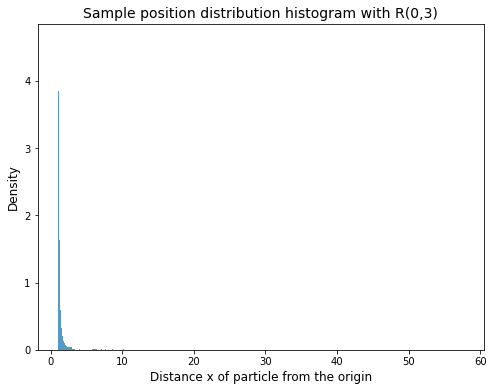

In [45]:
plt.figure(figsize = (8,6))
sns.histplot(total_recorded_x_3, stat = "density")

plt.title("Sample position distribution histogram with R(0,3)", fontsize = 14)
plt.xlabel("Distance x of particle from the origin", fontsize = 12)
plt.ylabel("Density", fontsize = 12);
plt.savefig("Possible position histogram with R(0,3)", dpi = 100)

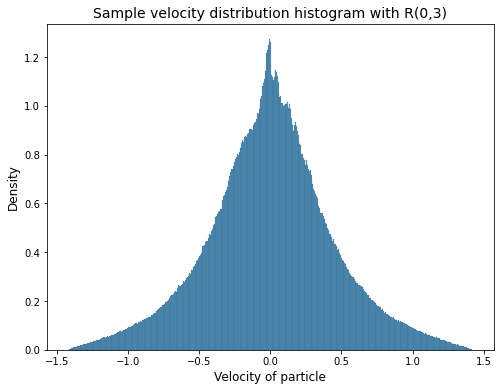

In [11]:
plt.figure(figsize = (8,6))
sns.histplot(total_recorded_v_3, stat = "density")

plt.title("Sample velocity distribution histogram with R(0,3)", fontsize = 14)
plt.xlabel("Velocity of particle", fontsize = 12)
plt.ylabel("Density", fontsize = 12)
plt.savefig("Possible velocity histogram with R(0,3)", dpi = 100);

#### Making a plot of position of the particle throughout a single simulation against time in order to visualise the simulation better.




total_recorded_x will be sliced into the x values for the particular simulation you wish to plot. There are 50000 x values per simulation so e.g. the 3rd simulation will run from the 150,001st number to the 200,000th number in total_recorded_x. But python indices start at 0 so spice from index 150,000 up to but not including index 200,000.

In [13]:
recorded_t = np.arange(0, n * timespan, timespan * 10)

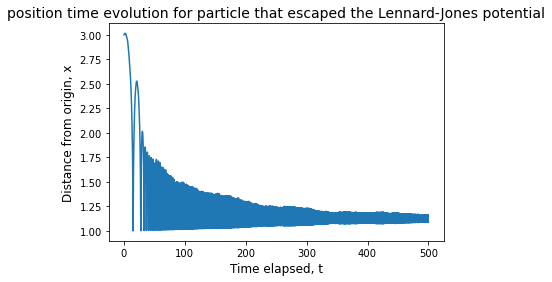

In [46]:
# Defining the amount of time elapsed for a simulation
#recorded_t = np.arange(0, n * timespan, timespan * 10) # The stepsize is ten times larger than the timespan as 
                                                                  # only every tenth position and velocity measurement 
                                                                  # are recorded


        
# s = number of the simulation you wish to plot the time evolution of.
s = 4
x_per_sim = total_recorded_x_3[int( ( ( (s-1) * n) ) /10 ) : int( ( ( (s-1) * n) + n) /10 )]
         
plt.plot(recorded_t, x_per_sim)
plt.xlabel("Time elapsed, t", fontsize = 12)
plt.ylabel("Distance from origin, x", fontsize = 12)
plt.title("position time evolution for particle that escaped the Lennard-Jones potential", fontsize = 14)

# Truncate recorded_t to show the oscillatory nature of the simulation
#plt.xlim(0, 100)
plt.savefig("Zoomed in time evolution of position of particle bound in Lennard-Jones potential", dpi = 100, 
            bbox_inches = "tight");

#### (c) Calculate the average velocity and the temperature from the equipartition theorem and discuss the relation between the observed temperature and the input one.

#### In order to get more accurate values of the average temperature, multiple simulations of the particle are run for the same conditions and the mean of all the average temperatures is gotten.

#### The same code from before is looped for the number of simulations we want to average over (m)

In [23]:
# Creating dictionaries that will store all average velocities and temperatures over the m simulations 
# These will be indexed by the value of sigma_R that was used for the simulations.
#v_avg_dict = {}
#T_avg_dict = {}

In [25]:
# Lists for recorded average velocity and temperature for every simulation
recorded_v_avg = []
recorded_T_avg = []

# Create empty list that the average velocity and temperature will be put into inside the corresponding dictionaries
v_avg_dict["mean velocity for R(0,"+str(sigma_R)+")"] = []
T_avg_dict["mean temperature for R(0,"+str(sigma_R)+")"] = []


# s = the simulation number we want to get the average velocity and temparature of
s = 1
while s < len(total_recorded_v_3) / (n/10) :
    
    # Splicing the recorded v for a single simulation out of the total list.
    recorded_v_per_simulation = total_recorded_v_3[int( ( ( (s-1) * n) ) /10 ) : int( ( ( (s-1) * n) + n) /10 )]

    # Calculating the average velocity for one simulation
    v_avg = sum(abs(recorded_v_per_simulation)) / len(recorded_v_per_simulation)

    # Calculating the average temperature for one simulation
    T_avg = v_avg**2

    # Record average velocity and temperature for each simulation
    #print("v_avg =", v_avg)
    recorded_v_avg.insert(j, v_avg)
    recorded_T_avg.insert(j, T_avg)
        
    s += 1
    #print("averages:",recorded_v_avg, recorded_T_avg)

# Append the average velocity and temperature over all simulations to the corresponding dictionaries.
v_avg_dict["mean velocity for R(0,"+str(sigma_R)+")"] = recorded_v_avg
T_avg_dict["mean temperature for R(0,"+str(sigma_R)+")"] = recorded_T_avg

#print("dictionary:", v_avg_dict, T_avg_dict)

# Converting dictionaries v_avg_dict and T_avg_dict into pandas DataFrames
v_avg_df = pd.DataFrame(v_avg_dict)
T_avg_df = pd.DataFrame(T_avg_dict)

In [27]:
v_avg_df

,"mean velocity for R(0,3)"
0,0.322634
1,0.372535
2,0.326115
3,0.373100
4,0.323949
...,...
94,0.361049
95,0.102401
96,0.373418
97,0.360987


In [28]:
T_avg_df


,"mean temperature for R(0,3)"
0,0.104093
1,0.138782
2,0.106351
3,0.139204
4,0.104943
...,...
94,0.130356
95,0.010486
96,0.139441
97,0.130312


Calculate the mean of v_avg and T_avg over all simulations


In [29]:
mean_v_avg = pd.Series([sum(v_avg_df["mean velocity for R(0,1)"])/len(v_avg_df["mean velocity for R(0,1)"]),
                   sum(v_avg_df["mean velocity for R(0,2)"])/len(v_avg_df["mean velocity for R(0,2)"]),
                   sum(v_avg_df["mean velocity for R(0,3)"])/len(v_avg_df["mean velocity for R(0,3)"])],
                       index = ["R(0,1)", "R(0,2)", "R(0,3)"])

mean_T_avg = pd.Series([sum(T_avg_df["mean temperature for R(0,1)"])/len(T_avg_df["mean temperature for R(0,1)"]),
                   sum(T_avg_df["mean temperature for R(0,2)"])/len(T_avg_df["mean temperature for R(0,2)"]),
                   sum(T_avg_df["mean temperature for R(0,3)"])/len(T_avg_df["mean temperature for R(0,3)"])],
                       index = ["R(0,1)", "R(0,2)", "R(0,3)"])

KeyError: 'mean velocity for R(0,1)'

In [170]:
# Checking method: both methods of getting the mean temperature over all simulations are equivalent.
mean2_T_avg = mean_v_avg**2

mean_T_avg == mean_T_avg

R(0,1)    True
R(0,2)    True
R(0,3)    True
dtype: bool

Isolate the simulations where the particle did not escape the lennard_jones potential and find T_avg and v_avg for these simulations.

In [180]:
mean_v_avg_captured = pd.Series([sum(v_avg_df[v_avg_df > 0.2]["mean velocity for R(0,1)"].dropna())/
                                len(v_avg_df[v_avg_df > 0.2]["mean velocity for R(0,1)"].dropna()),
                                sum(v_avg_df[v_avg_df > 0.2]["mean velocity for R(0,2)"].dropna())/
                                len(v_avg_df[v_avg_df > 0.2]["mean velocity for R(0,2)"].dropna()),
                                sum(v_avg_df[v_avg_df > 0.2]["mean velocity for R(0,3)"].dropna())/
                                len(v_avg_df[v_avg_df > 0.2]["mean velocity for R(0,3)"].dropna())],
                                index = ["R(0,1)", "R(0,2)", "R(0,3)"])

mean_T_avg_captured = mean_v_avg_captured**2

Isolate the simulations where the particle did escape the lennard_jones potential.

In [173]:
mean_v_avg_escaped = pd.Series([0, # There were no simulations with sigma_R = 1 and the particle escaped so the first entry = 0
                                sum(v_avg_df[v_avg_df < 0.2]["mean velocity for R(0,2)"].dropna())/
                                len(v_avg_df[v_avg_df < 0.2]["mean velocity for R(0,2)"].dropna()),
                                sum(v_avg_df[v_avg_df < 0.2]["mean velocity for R(0,3)"].dropna())/
                                len(v_avg_df[v_avg_df < 0.2]["mean velocity for R(0,3)"].dropna())],
                                index = ["R(0,1)", "R(0,2)", "R(0,3)"])

mean_T_avg_escaped = mean_v_avg_escaped**2

    mean velocity for R(0,1)  mean velocity for R(0,2)  \
0                        NaN                       NaN   
2                        NaN                       NaN   
4                        NaN                       NaN   
44                       NaN                       NaN   
56                       NaN                  0.066449   
63                       NaN                       NaN   
65                       NaN                       NaN   
67                       NaN                  0.116992   
81                       NaN                       NaN   
82                       NaN                       NaN   
87                       NaN                       NaN   
97                       NaN                       NaN   

    mean velocity for R(0,3)  
0                   0.074400  
2                   0.068856  
4                   0.094981  
44                  0.077967  
56                       NaN  
63                  0.078884  
65                  0.115593

R(0,1)    0.000000
R(0,2)    0.008413
R(0,3)    0.006951
dtype: float64

#### (d) Calculate the potential of mean force: UPMF = −kBT ln(1 + h(r)), where h(r) is the position distribution function, and compare it to the Lennard-Jones potential

To calculate the potential of the mean force, the position distribution function h(r) needs to be defined. 

To define this, the heights of the bars in the position distribution histogram are needed. Each bar is accessed using `histplot().patches` and the bar's height attribute is accessed using `bar.get_height()`. The height of each bar is stored into x_heights using a list comprehension.

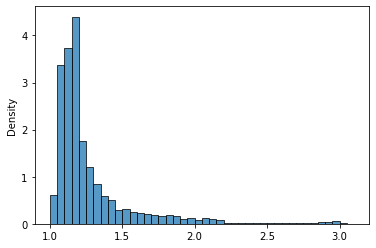

In [33]:
#x_heights = [bar.get_height()for bar in sns.histplot(recorded_x, stat = "density", bins = np.arange(1,34,1)).patches];
x_heights = [bar.get_height()for bar in sns.histplot(recorded_x, stat = "density", bins = np.arange(1,3.15,0.05)).patches];
x_heights = np.array(x_heights)

To check that x_heights stores the right values, recall that the area under the curve of the histogram equals 1. Therefore the sum of all elements of x_heights, multiplied by the width of the bins, 0.05, should equal 1:

In [34]:
sum(x_heights) * 0.05
#sum(x_heights) * 0.1
# Correct to machine precision

0.9999999999999997

In [35]:
# x_heights is now turned into a pandas series so the x positions, and their relative probabilities can be collected together

x_heights_series = pd.Series(x_heights, index = np.arange(1, 3.10, 0.05)) 
#x_heights_series = pd.Series(x_heights, index = np.arange(1, 33, 1)) 

Define h(r) as the relative height of the probability distribution that the particle is between r and r+dr away from the other particle at the origin. Therefore r = x, the position of the particle away from the origin. The probability to get an x value between 1.5 and 1.55 for instance, is the area of the 1.5 to 1.55 bin in the position distribution histogram. To get this area, just multiply the height of the 1.5 to 1.55 bin by its width, 0.05.

In [36]:
# Defining h(r) = h(x):
def h(x):
    return(x_heights_series[x]) # returns the probability associated with the position x away from the origin.
                                # Only works for values of x with x mod 0.05 = 0 between 0 and 4.

In [37]:
def Upmf(x):
    return -np.log(1 + h(x))

To compare Upmf with Ulennard-jones, they must be of the same scale, so they must both 

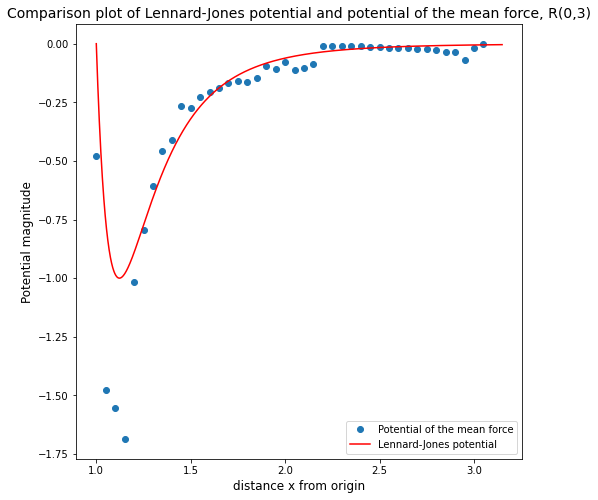

In [38]:
plt.figure(figsize = (8,8))
x = np.arange(1, 3.10, 0.05)
#x = np.arange(1, 33, 1)

plt.plot(x, Upmf(x), "o")

y = np.arange(1,3.15,0.001)
#y = np.arange(1,34,0.001)

LennardJones = 4*(1/y**12 - 1/y**6)
plt.plot(y, LennardJones, "r")
#plt.ylim(-1.5,0.5)
plt.ylabel("Potential magnitude", fontsize = 12)
plt.xlabel("distance x from origin", fontsize = 12)
plt.title("Comparison plot of Lennard-Jones potential and potential of the mean force, R(0,3)", fontsize = 14)
plt.legend(["Potential of the mean force","Lennard-Jones potential"]);
plt.savefig("Comparison plot for 500000 steps, R(0,3)",dpi = 100, bbox_inches = "tight")

In [53]:
# Exporting the raw data to Latex
print(v_avg_df.to_latex(index = True))

\begin{tabular}{lrrr}
\toprule
{} &  mean velocity for R(0,1) &  mean velocity for R(0,2) &  mean velocity for R(0,3) \\
\midrule
0  &                  0.349823 &                  0.346981 &                  0.074400 \\
1  &                  0.330785 &                  0.347085 &                  0.333107 \\
2  &                  0.333523 &                  0.359348 &                  0.068856 \\
3  &                  0.339839 &                  0.354607 &                  0.326694 \\
4  &                  0.322902 &                  0.329424 &                  0.094981 \\
5  &                  0.356415 &                  0.377801 &                  0.266545 \\
6  &                  0.343468 &                  0.331566 &                  0.248499 \\
7  &                  0.335740 &                  0.334239 &                  0.319694 \\
8  &                  0.331818 &                  0.353295 &                  0.357932 \\
9  &                  0.339561 &                  0.323503 &

In [54]:
print(T_avg_df.to_latex(index = True))

\begin{tabular}{lrrr}
\toprule
{} &  mean temperature for R(0,1) &  mean temperature for R(0,2) &  mean temperature for R(0,3) \\
\midrule
0  &                     0.122376 &                     0.120396 &                     0.005535 \\
1  &                     0.109419 &                     0.120468 &                     0.110960 \\
2  &                     0.111238 &                     0.129131 &                     0.004741 \\
3  &                     0.115491 &                     0.125746 &                     0.106729 \\
4  &                     0.104266 &                     0.108520 &                     0.009021 \\
5  &                     0.127031 &                     0.142733 &                     0.071046 \\
6  &                     0.117970 &                     0.109936 &                     0.061752 \\
7  &                     0.112721 &                     0.111716 &                     0.102204 \\
8  &                     0.110103 &                     0.124817 &   

In [167]:
print(mean_v_avg.to_latex(index = True))

\begin{tabular}{lr}
\toprule
{} &         0 \\
\midrule
R(0,1) &  0.344881 \\
R(0,2) &  0.338687 \\
R(0,3) &  0.316934 \\
\bottomrule
\end{tabular}



In [166]:
print(mean_T_avg.to_latex(index = True))

\begin{tabular}{lr}
\toprule
{} &         0 \\
\midrule
R(0,1) &  0.119052 \\
R(0,2) &  0.116400 \\
R(0,3) &  0.107607 \\
\bottomrule
\end{tabular}



In [181]:
print(mean_v_avg_captured.to_latex(index = True))

\begin{tabular}{lr}
\toprule
{} &         0 \\
\midrule
R(0,1) &  0.344881 \\
R(0,2) &  0.343779 \\
R(0,3) &  0.343177 \\
\bottomrule
\end{tabular}



In [182]:
print(mean_T_avg_captured.to_latex(index = True))

\begin{tabular}{lr}
\toprule
{} &         0 \\
\midrule
R(0,1) &  0.118943 \\
R(0,2) &  0.118184 \\
R(0,3) &  0.117770 \\
\bottomrule
\end{tabular}



In [175]:
print(mean_v_avg_escaped.to_latex(index = True))

\begin{tabular}{lr}
\toprule
{} &         0 \\
\midrule
R(0,1) &  0.000000 \\
R(0,2) &  0.091720 \\
R(0,3) &  0.083373 \\
\bottomrule
\end{tabular}



In [185]:
print(mean_T_avg_escaped.to_latex(index = True))

\begin{tabular}{lr}
\toprule
{} &         0 \\
\midrule
R(0,1) &  0.000000 \\
R(0,2) &  0.008413 \\
R(0,3) &  0.006951 \\
\bottomrule
\end{tabular}

